# Intermediate Task

Question: Are countries with higher YouTube penetration also happier?

let's use both of the data sets to answer these question

Let's make JOINS commented and other things

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as ptl
import seaborn as sns

happiness_df = pd.read_csv("/home/mikes/ChallengeDT/datasource/World-happiness-report-2024.csv")
users_df = pd.read_csv("/home/mikes/ChallengeDT/datasource/youtube-users-by-country-2025.csv")


## EDA for both of the data sets

Let's make a EDA for both data sets just to see if is there something particular to take in mind


Let's begin with happines data set



In [2]:
# Happines df general EDA
happiness_info = happiness_df.info()
happiness_shape = happiness_df.shape
happiness_null = happiness_df.isna().sum()
happiness_dup = happiness_df.duplicated().sum()

print(f"Data Frame INFO: {happiness_info}")
print(f"Data Frame SHAPE:{happiness_shape}")
print(f"Data Frame NULL: {happiness_null}")
print(f"Data Frame DUP: {happiness_dup}")


<class 'pandas.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country name                  143 non-null    str    
 1   Regional indicator            143 non-null    str    
 2   Ladder score                  143 non-null    float64
 3   upperwhisker                  143 non-null    float64
 4   lowerwhisker                  143 non-null    float64
 5   Log GDP per capita            140 non-null    float64
 6   Social support                140 non-null    float64
 7   Healthy life expectancy       140 non-null    float64
 8   Freedom to make life choices  140 non-null    float64
 9   Generosity                    140 non-null    float64
 10  Perceptions of corruption     140 non-null    float64
 11  Dystopia + residual           140 non-null    float64
dtypes: float64(10), str(2)
memory usage: 13.5 KB
Data Frame INFO: None
Data Fra

Now let's continue with users data frame

In [6]:
# Users df general EDA

users_info = users_df.info()
users_shape = users_df.shape
users_null = users_df.isna().sum()
users_dup = users_df.duplicated().sum()


print(f" Users DF INFO: {users_df.info()}")
print("\n\n")
print(f"Users DF SHAPE: {users_shape}")
print("\n\n")
print(f"User DF NULL: {users_null}")
print("\n\n")
print(f"User DF DUP: {users_dup}")

<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 6 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   flagCode                              87 non-null     str    
 1   country                               87 non-null     str    
 2   YouTubeUsers_TotalUsers_Num_2024Feb   87 non-null     int64  
 3   YouTubeUsers_Penetration_Pct_2024Feb  87 non-null     float64
 4   YouTubeUsersJuly2023                  87 non-null     float64
 5   YouTubeUsersPenetrationJuly2023       87 non-null     float64
dtypes: float64(3), int64(1), str(2)
memory usage: 4.2 KB
<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 6 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   flagCode                              87 non-null     str    
 1   country           

# First Impresions about both Data sets

HAPPINESS DATA SET:

- This data frame has 12 columns and 143 rows.

- This data fram has null values (21 in total on diferents columns)

- This data frame hasn't duplicates

USERS DATA SET:

- This data frame has 87 rows and 6 columns 

- This data frame hasn't duplicates

- This data frame hasn't nulls

# Let's move forward with the real work

According with what we see on the previous EDA analysis of Happiness ir hasn't has a column called "happines" instead it has a column called "Ladder Score" so we need to rename it to "happines" and the "country name" to "country" as well.

In [12]:
happiness_df = happiness_df.rename(columns={"Ladder score" : "happiness"})
happiness_df = happiness_df.rename(columns={"Country name" : "country"})

users_df = users_df.rename(columns={"YouTubeUsers_Penetration_Pct_2024Feb" : "penetration_2024"})




#print(happiness_df.head())

- Now let's merge both dataframes in an inner join over "country"



In [13]:
merged_df = pd.merge(users_df, happiness_df, on="country", how="inner")

print(len(merged_df))

set(users_df["country"]) - set(happiness_df["country"])


80


{'Czech Republic',
 'Hong Kong',
 'Oman',
 'Puerto Rico',
 'Qatar',
 'Taiwan',
 'Turkey'}

In [14]:

set(happiness_df["country"]) - set(users_df["country"])

{'Afghanistan',
 'Albania',
 'Armenia',
 'Azerbaijan',
 'Benin',
 'Botswana',
 'Burkina Faso',
 'Cambodia',
 'Cameroon',
 'Chad',
 'China',
 'Comoros',
 'Congo (Brazzaville)',
 'Congo (Kinshasa)',
 'Cyprus',
 'Czechia',
 'Eswatini',
 'Ethiopia',
 'Gabon',
 'Gambia',
 'Georgia',
 'Guinea',
 'Hong Kong S.A.R. of China',
 'Iran',
 'Ivory Coast',
 'Jamaica',
 'Kazakhstan',
 'Kosovo',
 'Kyrgyzstan',
 'Laos',
 'Lesotho',
 'Liberia',
 'Libya',
 'Luxembourg',
 'Madagascar',
 'Malawi',
 'Mali',
 'Malta',
 'Mauritania',
 'Mauritius',
 'Moldova',
 'Mongolia',
 'Montenegro',
 'Mozambique',
 'Myanmar',
 'Namibia',
 'Nepal',
 'Niger',
 'North Macedonia',
 'Russia',
 'Sierra Leone',
 'State of Palestine',
 'Taiwan Province of China',
 'Tajikistan',
 'Tanzania',
 'Togo',
 'Turkiye',
 'Uganda',
 'Uzbekistan',
 'Venezuela',
 'Yemen',
 'Zambia',
 'Zimbabwe'}

80 matched; 7 YouTube unmatched (4 name mismatches + 3 coverage gaps); 63 happiness unmatched because that file is larger

- Now let's see the correlation between Youtube penetration and happiness in countries


In [ ]:
pearson_r = merged_df["penetration_2024"].corr(merged_df["happiness"], method="pearson")
spearman_rho = merged_df["penetration_2024"].corr(merged_df["happiness"], method="spearman")

print(pearson_r, spearman_rho)

0.5254490201184571 0.565286699482001


# Let's make the scattter

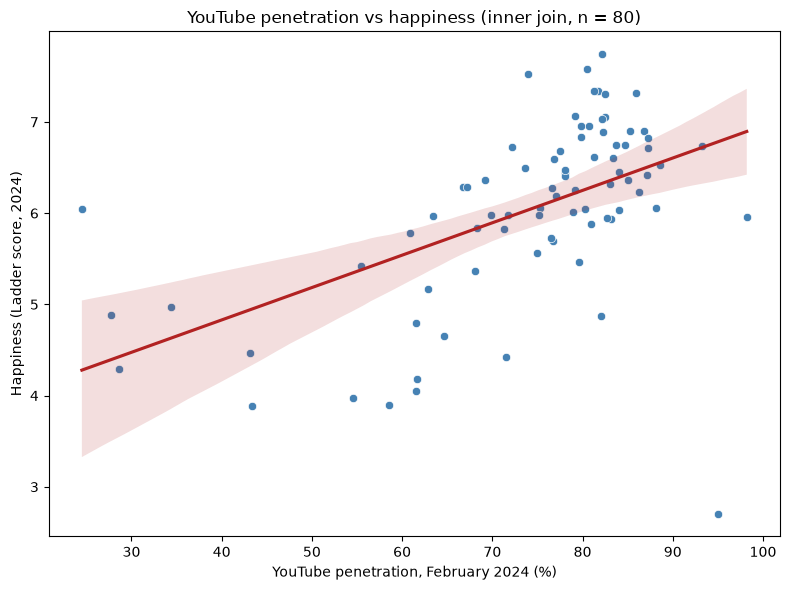

In [16]:
figures_dir = Path("/home/mikes/ChallengeDT/outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig, ax = ptl.subplots(figsize=(8,6))

sns.scatterplot(
    data=merged_df,
    x="penetration_2024",
    y="happiness",
    ax=ax,
    color="steelblue",
)


sns.regplot(
    data=merged_df,
    x="penetration_2024",
    y="happiness",
    scatter=False,
    ax=ax,
    color="firebrick",
)
ax.set_xlabel("YouTube penetration, February 2024 (%)")
ax.set_ylabel("Happiness (Ladder score, 2024)")
ax.set_title("YouTube penetration vs happiness (inner join, n = 80)")
fig.tight_layout()
fig.savefig(figures_dir / "03_penetration_vs_happiness.png", dpi=150)
ptl.show()

# conclusion 

Among the 80 countries in the inner join, higher YouTube penetration tends to go with higher Ladder scores. Pearson r≈0.53 and Spearman, ρ≈0.57 are a moderate positive association; the two methods agree, so the result is not an artifact of one formula. The scatter rises to the right but is spread out, so penetration is not a tight predictor of happiness. At least one country combines very high penetration with very low happiness, which warns against a simple “more YouTube, more happiness” story. This is a country-level association, not evidence that YouTube causes happiness.